### 智能体优化-计划与执行

创建工具
***
- 基于https://tavily.com/ 创建搜索工具

In [2]:
from google.protobuf import reflection
from langchain_tavily import TavilySearch
from dotenv import load_dotenv
import os

from Agent_demo.langchain_memory import workflow
from sympy.geometry.entity import translate
from torch.distributed._shard import checkpoint
from urllib3 import request

# 加载.env文件
load_dotenv()
tools = [
    TavilySearch(max_results=3, tavily_api_key=os.getenv("TAILLY_API_KEY")),
]

定义简单智能体

In [3]:
from langchain_deepseek import ChatDeepSeek
from langchain.agents import create_agent
# 使用DeepSeek模型

llm = ChatDeepSeek(
    model="deepseek-v4-flash",
    temperature=0,
    api_key=os.getenv("DEEP_SEEK_API_KEY"),
    base_url=os.getenv("DEEP_SEEK_BASE_URL"),
    reasoning_effort=None
)

prompt = "你是一个小助手"
agent_executor = create_agent(llm, tools, system_prompt=prompt)


In [20]:
result = agent_executor.invoke({"messages": [("user", "谁是2026年最火的AI Agent项目？")]})
print(result["messages"][-1].content)

根据我搜索到的信息，2026年最火的AI Agent项目基本可以确定是 **OpenClaw（"龙虾"）**。下面为你详细梳理：

## 🏆 2026年最火：OpenClaw（龙虾）

这是一个开源的个人AI Agent框架，2026年初在GitHub上现象级爆火，被广泛认为是"继ChatGPT之后最重要的一次个人生产力革命"。

**核心亮点：**
- 🚀 **创纪录增长**：短短数月星标数突破33万+（有资料称截至2026年中已超38万），登顶GitHub历史增速第一，超越了React 13年的积累，成为GitHub史上最热门的开源项目之一
- 🦞 **"龙虾"昵称**：因其名字OpenClaw（Claw=爪子）被国内社区戏称为"小龙虾"，2026年春节后在国内彻底引爆，掀起"养龙虾"热潮
- 💻 **真能干活**：与传统Chatbot完全不同，它能7×24小时运行，自主操控浏览器、编写代码、读写文件、执行系统命令，是"数字员工"而非"聊天机器人"
- 🔒 **本地优先**：数据跑在自己的设备上，无需经过厂商云API
- 📱 **全平台接入**：支持WhatsApp、Telegram、Discord、微信、企业微信、飞书、钉钉等50+通讯平台

**开发者故事**：由奥地利独立程序员 **Peter Steinberger** 仅用一小时做出原型，后来他于2026年2月加入OpenAI（参与"下一代个人Agent"研发），但OpenClaw保持开源，由独立基金会治理。

## 🥈 其他值得关注的热门项目

| 项目 | 特点 |
|------|------|
| **Hermes Agent**（Nous Research）| 与OpenClaw并称2026年最火的两款开源个人AI Agent |
| **Manus AI** | 通用型云端Agent，2025年爆火，但2026年用户留存下滑，被开源"龙虾"分流 |
| **Claude Code / Cursor / Devin** | 编程/IDE领域的头部Agent |
| **阿里云 CoPaw** | 2026年2月阿里推出的自研AI智能体，加入"龙虾大战" |

## 一句话总结

> **2026年最火的是OpenClaw（"龙虾"）**——它标志AI行业从"大模型参数比拼"迈入"智能体落地应用

定义state

In [5]:
import operator
from typing import Annotated, List, Tuple
from typing_extensions import TypedDict

# 定义一个数据结构来表示计划执行的结果
class PlanExcute(TypedDict):
    input: str
    plan: List[str]
    past_steps: Annotated[List[Tuple], operator.add]
    response: str

规划阶段

In [6]:
from pydantic import BaseModel, Field

class Plan(BaseModel):
    """未来需要遵循的计划"""
    steps: List[str] = Field(
        description="需要遵循的不同步骤， 应该按排序数序排列",
    )

In [7]:
from langchain_core.prompts import ChatPromptTemplate

planner_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """针对给定的目标，制定一个简单的逐步计划。\
                每一步只描述需要做什么，不要执行具体操作，也不要给出最终答案。\
                步骤应该是可操作的搜索或查询任务，而不是结论。——不要跳过步骤。 \
                请严格按照以下 JSON 格式输出，不要添加任何其他内容：
                {{"steps": ["步骤1", "步骤2", "步骤3", ...]}}"""
        ),
        ("placeholder", "{messages}"),
    ]
)

planner = planner_prompt | llm.with_structured_output(Plan, method="json_mode")

In [8]:
planner.invoke(
    {
        "messages": [
            ("user", "中国女子短跑最快的选手是谁？")
        ]
     }
)

Plan(steps=['搜索“中国女子100米全国纪录”以获取该项目的最高纪录', '搜索“中国女子200米全国纪录”以获取该项目的最高纪录', '打开中国田径协会官方网站，核实上述纪录的准确性', '比较两个纪录的时间，确认哪个项目的最快成绩用时更短', '根据用时更短的项目，搜索该纪录的保持者信息', '验证保持者的国籍和性别，确保为中国女子选手'])

重新计划（优化计划）Replan

In [18]:
from typing import Union

class Response(BaseModel):
    """用户的响应"""
    response: str

class Act(BaseModel):
    """需要执行的操作"""
    action: Union[Response, Plan] = Field(description="需要执行的操作。如果你想直接影响用户，就使用Response。如果需要进一步使用工具来获取答案，就使用Plan。")

replanner_prompt = ChatPromptTemplate.from_template(
    """针对给定的目标，制定一个简单的逐步计划。\
    该计划应包括单独的任务，如果正确执行这些任务，将最终导致目标的实现。不要添加任何多余的步骤。\
    最后一步的结果应该是最终的答案。确保每一步都包含所需的所有信息——不要跳过步骤。\
    你的目标是：{input}
    你的原始计划是：{plan}
    你目前已完成以下步骤：{past_steps}
    请根据当前情况更新你的计划。如果不需要更多步骤就可以直接响应用户，请返回响应。否则，请补充计划。\
    只需添加仍然需要完成的步骤，不要将已经完成的步骤作为计划的一部分返回。\
    请严格按照以下 JSON 格式输出，不要添加任何其他内容：
    - 如果需要回复用户：{{"action": {{"response": "你的回答内容"}}}}
    - 如果需要继续计划：{{"action": {{"steps": ["步骤1", "步骤2", "步骤3", ...]}}}}"""
)

replanner = replanner_prompt | llm.with_structured_output(Act, method="json_mode")

创建graph

In [10]:
from langgraph.graph import END

# 异步函数 execute_step
# 执行计划中的一个步骤
# 输入参数 state 包含当前计划（plan），函数会格式化计划并执行第一步。
async def execute_step(state: PlanExcute):
    plan = state["plan"] # 获取当前计划
    # 将计划格式化为字符串，每一步带有序号
    plan_str = "\n".join(f"{i+1}. {step}" for i, step in enumerate(plan))
    task = plan[0] # 获取计划的第一步任务
    # 格式化提示词，告知代理需要执行计划的第一步
    task_formatted = f"""针对一下计划：
                      {plan_str}\n\n你的任务是：执行第{1}步：{task}。"""
    # 调用代理执行器，传递格式化后的任务
    agent_response = await agent_executor.ainvoke(
        {"messages": [("user", task_formatted)]}
    )
    # 返回已完成的步骤，包括任务和代理响应
    return {
        "past_steps": [(task, agent_response["messages"][-1].content)]
    }

# 异步函数 plan_step
# 根据用户输入生成完整的计划。
# 输入参数 state 包含用户输入（input），函数会调用规划器生成计划。
async def plan_step(state: PlanExcute):
    # 调用计化生成器，传递用户的输入
    plan = await planner.ainvoke(
        {"messages": [("user", state["input"])]}
    )
    # 返回生成的计划
    return {"plan": plan.steps}

# 异步函数 replan_step
# 根据当前计划和已完成步骤，重新计划。
# 输入参数 state 包含当前计划（plan）、已完成步骤（past_steps）、用户输入（input），函数会调用重新规划器生成新的计划。
async def replan_step(state: PlanExcute):
    # 调用重新规划器，传递当前计划、已完成步骤和用户输入
    output = await replanner.ainvoke(state)
    # 如果输出是用户的响应，直接返回响应
    if isinstance(output.action, Response):
        return {"response": output.action.response}
    # 否则，返回新的计划
    else:
        return {"plan": output.action.steps}

# 异步函数 should_end
# 检查是否应该结束任务。
# 输入参数 state 包含当前计划（plan）、已完成步骤（past_steps），函数会返回结束消息。
async def should_end(state: PlanExcute):
    # 如果状态中存在响应并且响应不为空，则返回 END 表示任务结束
    if "response" in state and state["response"]:
        return END
    # 否则，返回 "agent" 表示继续执行任务
    else:
        return "agent"


In [11]:
from langgraph.graph import StateGraph, START

# 创建一个状态图，表示工作流
workflow = StateGraph(PlanExcute)
# 添加计划节点
workflow.add_node("planner", plan_step)
# 添加执行步骤节点
workflow.add_node("agent", execute_step)
# 添加重新规划节点
workflow.add_node("replan", replan_step)

# 添加从起点到计划节点的边
workflow.add_edge(START, "planner")
# 添加从计划节点到执行步骤节点的边
workflow.add_edge("planner", "agent")
# 添加从执行步骤节点到重新规划节点的边
workflow.add_edge("agent", "replan")
# 添加条件边
workflow.add_conditional_edges(
    "replan",
    # 接下来冲入一个函数，用于确定下一个节点的调用。
    should_end,
    ["agent", END], # 根据条件选择继续执行或结束工作流
)
# 最后。编译工作流！
# 这会将状态图编译为一个可执行的图对象（LangChain 的 Runnable），
# 意味着你可以像使用其他 Runnable 一样调用它。
app = workflow.compile()


查看图结构

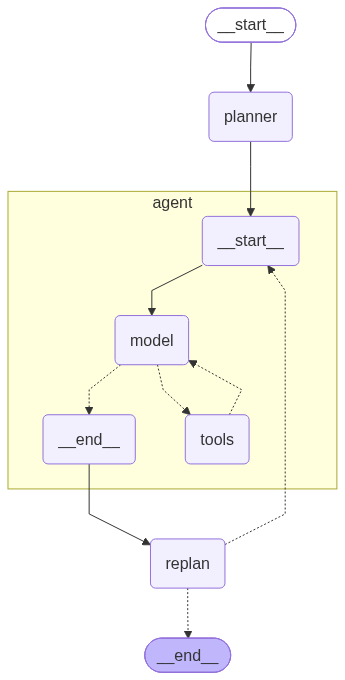

In [12]:
from IPython.display import Image, display
display(Image(app.get_graph(xray=True).draw_mermaid_png()))

In [19]:
config = {"recursion_limit": 10}
inputs = {"input": "中国女子短跑最快的选手是谁？"}
async for event in app.astream(inputs, config=config):
    for key, value in event.items():
        if key != "__end__":
            print(value)


{'plan': ['明确“短跑”具体指哪些项目（如100米、200米等）', '搜索中国女子100米短跑全国纪录', '搜索中国女子200米短跑全国纪录', '若需要，搜索中国女子400米短跑全国纪录', '查询中国田径协会或权威体育数据库中的纪录信息', '比较各项目纪录的最短时间，找出成绩最快的选手', '验证该选手的纪录是否仍有效并确认其身份']}
{'past_steps': [('明确“短跑”具体指哪些项目（如100米、200米等）', '# 第1步：明确"短跑"具体指哪些项目\n\n"短跑"（Sprint）在田径运动中有明确的国际分类标准。以下是具体界定：\n\n## 国际通用分类（世界田联标准）\n\n| 类别 | 项目 | 说明 |\n|------|------|------|\n| **短跑** | **100米** | 最经典的短跑项目，被视为"飞人大战" |\n| **短跑** | **200米** | 弯道+直道的短跑项目 |\n| **短跑** | **400米** | 被称为"最长的短跑"，常被归入短跑范畴 |\n| 短跑（室内） | 60米 | 主要在室内赛进行，中国女子全国纪录通常单列 |\n\n> 注：800米及以上属于**中距离跑**，5000米及以上属于**长距离跑**，100米栏/400米栏等属于**跨栏项目**，通常不归入"短跑"范畴。\n\n## 关于400米的归属说明\n\n- 部分分类体系把400米归入"短跑"（sprint），部分归类为"短距离开放类"；\n- 在多数全国纪录统计和运动员归类中，**400米通常与100米、200米并列在短跑类别下**；\n- 世界田联的Sprint板块即涵盖 **100m / 200m / 400m** 三个项目。\n\n## 对本次研究计划的界定\n\n结合你的计划第2~4步（搜索100米、200米、若有需要再搜400米），建议本次"短跑"研究范围明确为：\n\n> **✅ 核心项目：100米、200米（必查）**\n> **✅ 扩展项目：400米（可选，用于完整性对比）**\n> **❌ 不纳入：60米（室内单列）、跨栏、接力、800米及以上**\n\n---\n\n**下一步**：按此界定，可以开始执行第2步——搜索中国女子100米短跑全国纪录。需要我继续吗？')]}
{'

### 智能体优化-反思

首先定一个最简单的任务：撰写五段式文章

In [2]:
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
import os
# 加载环境变量
load_dotenv()
# 创建聊天提示模板
prompt = ChatPromptTemplate.from_messages(
    [
        (
            # 系统提示词
            "system",
            "你是一名专业的文章助手，负责撰写优质的五段式文章。"
            "请根据用户的请求生成最佳的文章。"
            "如果用户提供了反馈或批评，请根据之前的尝试生成修订版本的文章。"
        ),
        # 消息占位符，用于动态插入用户和AI的消息
        MessagesPlaceholder(variable_name="messages"),
    ]
)

# 配置大语言模型DeepSeek
llm = ChatDeepSeek(
    model="deepseek-v4-flash",
    temperature=0,
    api_key=os.getenv("DEEP_SEEK_API_KEY"),
    base_url=os.getenv("DEEP_SEEK_BASE_URL"),
    reasoning_effort=None
)

# 将提示词模版与大语言模型连接，用于生成内容
generate = prompt | llm


试一下不做反思的效果

In [2]:
essay = ""
request = HumanMessage(
    content="写一篇关于科学用脑的文章，要求内容丰富，语言通俗易懂。"
)
for chunk in generate.stream({"messages": [request]}):
    print(chunk.content, end="")
    essay += chunk.content

好的，请看我为您撰写的这篇关于科学用脑的文章。

---

## 唤醒沉睡的巨人：科学用脑，让生命更高效

在信息爆炸的今天，我们的大脑就像一台24小时不关机的超级计算机，永不停歇地接收、处理和储存着海量信息。然而，大多数人对自己最为宝贵的“生物硬件”知之甚少。我们往往凭感觉、靠蛮力去学习和工作，却忽略了大脑运行的底层规律。其实，脑科学并非遥远实验室里的冰冷术语，它与我们每个人的日常生活息息相关。学会科学用脑，无异于掌握了一把解锁自身潜能的钥匙。今天，我们就来聊一聊，如何读懂并善用这个“沉睡的巨人”。


### 一、认识你的“超级CPU”：大脑的运作原理

想用脑，先懂脑。我们的大脑虽然只占体重的2%左右，却要消耗全身约20%的能量，这足以证明它的“高功耗”特性。它并非一个均匀发光的灯泡，而是由多个功能各异的区域组成的精密网络。想象一下，额叶就像一位运筹帷幄的总指挥官，负责我们的决策、计划和专注力；颞叶则是“中央档案馆”，掌管着听觉和语言记忆；而枕叶则像一位专业的美术师，处理着视觉信息。

更奇妙的是，大脑内部依靠“神经元”传递信息。每个神经元通过突触与其他神经元相连，形成一个无比庞大的网络。我们学习的每一个新知识、掌握的每一个新技能，本质上都是在这个网络中建立了一条新的连接。民间常说的“脑子越用越灵”，在科学上完全成立，因为新的刺激会促使神经元“长芽”，让网络更加密集。同时，大脑也是“用进废退”的典范——长期不用的连接会被修剪掉，如同园林师傅修剪枝叶，让重要的通道更加顺畅。理解了这些原理，我们便能明白，科学用脑的第一步，就是顺应大脑的运行逻辑。


### 二、按部就班，张弛有度：学会“用”的艺术

既然大脑如此精妙，我们该如何科学地“使唤”它呢？首要法则就是“定力”。大脑在专注和涣散时，耗能方式截然不同。当我们沉浸在某一项任务中时，大脑会进入“心流”状态，能耗极高但很高效。然而，这种状态非常脆弱，容易被手机通知等干扰打断。所以，善用大脑，就要像狙击手一样，在关键时刻保持绝对专注。

这就引出了第二个法则：“合理地偷懒”。我们可能听过“一万小时定律”，但大脑并非一台不知疲倦的机器，它的注意力资源是有限的。研究表明，高强度专注一段时间后（通常为45-90分钟），大脑的神经递质就会耗尽，效率会断崖式下跌。与其靠咖啡硬撑，不如顺应生理规律，采用“番茄工作法”，每工作2

构建反思

In [3]:
# 构建反思提示词模版
reflection_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "你是一名教师，负责对文章提交进行评分。"
            "生成对用户提交的文章的批评意见和建议。"
            "提供详细的建议，包括对文章长度、深度、风格等方面的要求。",
        ),
        # 消息占位符，用于动态插入用户和AI的消息
        MessagesPlaceholder(variable_name="messages"),
    ]
)
# 将反思提示词模版与大语言模型连接，用于生成反馈内容
reflect = reflection_prompt | llm

手动进行反思

In [4]:
refilection = ""
for chunk in reflect.stream({"messages": [request, HumanMessage(content=essay)]}):
    print(chunk.content, end="")
    refilection += chunk.content

作为教师，我认真阅读了你的文章《唤醒沉睡的巨人：科学用脑，让生命更高效》。整体来看，这篇文章立意积极、结构清晰、语言生动，是一篇具有传播价值的科普作品。你能将脑科学知识与生活经验相结合，运用大量比喻让内容“接地气”，这点非常值得肯定。不过，在“科学准确性”“内容深度”“实用指导性”和“语言分寸感”上，还有一些可以打磨和提升的空间。下面，我具体谈谈我的批评与建议。

---

### 一、值得肯定的优点

1. **结构层次分明，逻辑顺畅**  
   从“认识大脑”到“用脑艺术”，再到“营养与睡眠”，最后落到“神经可塑性”，层层递进，符合认知规律，读者跟随文章能形成清晰的知识脉络。

2. **比喻使用得当，通俗易懂**  
   将大脑比作“超级CPU”“沉睡的巨人”，把专注比作“狙击手”，把熬夜比作“透支房贷”，既生动又有记忆点，完全契合“语言通俗易懂”的要求。

3. **科学依据基本准确**  
   大脑占比与耗能、额叶/颞叶/枕叶的功能、“用进废退”、睡眠中的脑脊液清理、伦敦出租车司机的海马体等，都有真实的科学研究背景，说明你阅读过相关资料，态度认真。

4. **结尾有号召力**  
   用“唤醒沉睡的巨人”首尾呼应，并落到“早睡半小时”“专注工作一小时”等微小行动，能激发读者的行动意愿。

---

### 二、需要改进的地方与具体建议

#### 1. 深度：个别科学表述过于简化，可能造成误导

- **“神经递质耗尽”一说不够严谨**  
  你写道：“高强度专注一段时间后，大脑的神经递质就会耗尽，效率会断崖式下跌。”事实上，注意力下降是复杂的神经过程，涉及多巴胺、去甲肾上腺素等递质的浓度变化，但“耗尽”并不科学，且不同递质功能不同。建议改为类似“大脑中与注意力相关的神经递质浓度下降，导致效率降低”或“脑内能量代谢产物堆积，使人感到疲劳”。

- **“睡眠清除淀粉样蛋白”需要限定条件**  
  这一结论主要来自动物实验，且机制仍在研究中。你可以加上“研究提示”“可能”等限定语，增强严谨性。比如：“近年来的研究提示，深度睡眠时脑脊液会加速清除大脑中的代谢废物，包括与阿尔茨海默病相关的淀粉样蛋白。”这样既通俗又准确。

- **“大脑消耗全身约20%的能量”可以更精确**  
  一般说“大脑约占体重2%，却消耗约20%的氧气和葡萄糖，是耗能最

定义graph

In [5]:
from typing import Annotated, List
from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from typing_extensions import TypedDict

class State(TypedDict):
    # 定义状态类型，其中消息列表使用‘add_messages’进行注解
    messages: Annotated[List, add_messages]

# 生成节点：处理生成的逻辑
async def generation_node(state: State) -> State:
    # 调用生成器的异步方法，根据当前状态的消息生成新的消息
    return {"messages": [await generate.ainvoke(state["messages"])]}

# 反思节点：处理反思和反馈的逻辑
async def reflection_node(state: State) -> State:
    # 需要调整的其他消息
    cls_map = {"ai": HumanMessage, "human": AIMessage}
    # 第一条消息是用户的原始请求，我们所有节点中保持不变
    translated = ([state["messages"][0]] +
                  [cls_map[msg.type](content=msg.content) for msg in state["messages"][1:]])
    # 调用反思器的异步方法，处理调整后的消息
    res = await reflect.ainvoke(translated)
    # 将反思的输出视为生成器的用户反馈
    return {"messages": [HumanMessage(content=res.content)]}

# 创建状态图构建器
builder = StateGraph(State)
# 添加生成节点
builder.add_node("generate", generation_node)
# 添加反思节点
builder.add_node("reflect", reflection_node)
# 添加从起始节点到生成节点的边
builder.add_edge(START, "generate")

# 定义是否继续的条件（条件边）
def should_continue(state: State):
    if len(state["messages"]) > 6:
        # 如果消息数量超过6，则结束（相当于3次迭代后结束）
        return END
    # 否则继续到反思节点
    return "reflect"
# 添加条件边，根据条件决定下一步是结束还是进入反思节点
builder.add_conditional_edges("generate", should_continue)
# 添加从反思节点到生成节点的边
builder.add_edge("reflect", "generate")
# 使用内存保存器作为检查点
memory = MemorySaver()
# 编译状态图，使用检查点保存器
graph = builder.compile(checkpointer=memory)


config = {"configurable": {"thread_id": 1}}
async for event in graph.astream(
        {
            "messages": [
                HumanMessage(content="写一篇关于科学用脑的文章，要求内容丰富，语言通俗易懂。字数控制在800到1000字之间。")
            ],
        },
        config,
):
    print(event)
    print("="*50)


{'generate': {'messages': [AIMessage(content='科学用脑，让大脑高效运转\n\n你有没有过这样的体验：熬夜背书，第二天却忘得一干二净；连着学习好几个小时，效率却越来越低。问题往往出在用脑方式上。大脑是人体最精密的器官，虽然只占体重的2%，却要消耗20%的能量，就像一台需要精心呵护的超级计算机。想让它高效运转，就要掌握它的“脾气”，科学用脑。\n\n先说说睡眠。睡眠绝不是偷懒，而是大脑的“美容时刻”。当我们睡着后，脑脊液会像温柔的流水一样冲刷大脑，带走白天产生的“垃圾”；同时，海马体还会把白天学到的内容“搬家”到长期记忆库。如果长期熬夜，大脑得不到清理，记忆力和判断力就会直线下降，效果甚至比喝醉还糟糕。所以，与其熬夜刷题，不如睡足七八小时，这才是“磨刀不误砍柴工”。\n\n其次要顺应生物钟，劳逸结合。早晨是大脑最清醒的时候，适合做背单词、解析难题等“硬任务”；中午饭后人容易犯困，不妨做些整理笔记、订正错题之类的“软任务”。这里分享一个“番茄工作法”：集中精力25分钟，然后休息5分钟，站起来走一走，让大脑“喘口气”。这种小节奏循环，比一口气学上两小时更高效，因为大脑长时间紧张也会“死机”。\n\n另外，科学用脑还离不开营养、运动和好情绪。大脑要工作，就得吃好喝好。鸡蛋、牛奶、鱼类和坚果里的蛋白质、Omega-3脂肪酸，都是大脑喜爱的“燃料”，就像优质汽油让汽车跑得又快又稳；而高糖高油的零食虽然味美，却会让大脑变得迟钝。运动同样重要，慢跑、跳绳、快走都能促进脑部血液循环，让大脑吸收更多氧气和养分，还能帮助分泌一种叫“脑源性神经营养因子”的“肥料”，让脑细胞长得更健壮。至于情绪，总是焦虑或压抑的人，如同电脑塞满了垃圾程序，转不动；心情愉快时，多巴胺和血清素会让人更专注、记得更牢。\n\n最后，我们要避开一些用脑的误区。有人说“人脑只开发了10%”，这早被科学否定了，脑成像显示，大脑几乎每一个区域都在工作，没有谁可以“闲置”。还有人迷信临考前突击，殊不知这种疲劳战术，只会制造虚假的熟悉感，没过几天就忘光；更好的做法是隔几天再复习一次，主动合上书“考考自己”，这样记忆才扎实。科学用脑并不神秘，它只是意味着好好睡觉、合理安排时间、吃好动好、心情舒畅。这颗“超级计算机”陪伴我们一生，善待它，它才会全力帮助我们学习、工作和创造。从今天起，让

查看详细过程

In [6]:
state = graph.get_state(config)
ChatPromptTemplate.from_messages(state.values["messages"]).pretty_print()

================================ Human Message =================================

写一篇关于科学用脑的文章，要求内容丰富，语言通俗易懂。字数控制在800到1000字之间。

================================== Ai Message ==================================

科学用脑，让大脑高效运转

你有没有过这样的体验：熬夜背书，第二天却忘得一干二净；连着学习好几个小时，效率却越来越低。问题往往出在用脑方式上。大脑是人体最精密的器官，虽然只占体重的2%，却要消耗20%的能量，就像一台需要精心呵护的超级计算机。想让它高效运转，就要掌握它的“脾气”，科学用脑。

先说说睡眠。睡眠绝不是偷懒，而是大脑的“美容时刻”。当我们睡着后，脑脊液会像温柔的流水一样冲刷大脑，带走白天产生的“垃圾”；同时，海马体还会把白天学到的内容“搬家”到长期记忆库。如果长期熬夜，大脑得不到清理，记忆力和判断力就会直线下降，效果甚至比喝醉还糟糕。所以，与其熬夜刷题，不如睡足七八小时，这才是“磨刀不误砍柴工”。

其次要顺应生物钟，劳逸结合。早晨是大脑最清醒的时候，适合做背单词、解析难题等“硬任务”；中午饭后人容易犯困，不妨做些整理笔记、订正错题之类的“软任务”。这里分享一个“番茄工作法”：集中精力25分钟，然后休息5分钟，站起来走一走，让大脑“喘口气”。这种小节奏循环，比一口气学上两小时更高效，因为大脑长时间紧张也会“死机”。

另外，科学用脑还离不开营养、运动和好情绪。大脑要工作，就得吃好喝好。鸡蛋、牛奶、鱼类和坚果里的蛋白质、Omega-3脂肪酸，都是大脑喜爱的“燃料”，就像优质汽油让汽车跑得又快又稳；而高糖高油的零食虽然味美，却会让大脑变得迟钝。运动同样重要，慢跑、跳绳、快走都能促进脑部血液循环，让大脑吸收更多氧气和养分，还能帮助分泌一种叫“脑源性神经营养因子”的“肥料”，让脑细胞长得更健壮。至于情绪，总是焦虑或压抑的人，如同电脑塞满了垃圾程序，转不动；心情愉快时，多巴胺和血清素会让人更专注、记得更牢。

最后，我们要避开一些用脑的误区。有人说“人脑只开发了10%”，这早被科学否定了，脑成像显示，大脑几乎每一个区域都在工作，没有谁可以“闲置”。还有